# AAAA

In [1]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../..")))


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

from src.methods import MultivariateACTest, DistanceCorrelationTest, CanonicalCorrelationTest
from src.solvers.weighted_network import ASE
from ecv_rank import *

In [2]:
edges = pd.read_csv("data/edges.csv")
nodes = pd.read_csv("data/nodes.csv")

In [3]:
edges.rename(columns={edges.columns[0]: "source"}, inplace=True)
edges.columns = [x.strip() for x in edges.columns]

nodes.rename(columns={nodes.columns[0]: "index"}, inplace=True)
nodes.columns = [x.strip() for x in nodes.columns]

In [4]:
edges.head()

,source,target,weight,nfw,gsw,committee
0,0,17,1,0.012987,0.003750,0
1,0,42,2,0.014649,0.013174,0
2,0,125,1,0.006369,0.001517,0
3,0,158,22,10.507576,0.628911,0
4,0,199,5,0.678571,0.404255,0


In [5]:
nodes.head()

,index,name,sex,born,party,partyname,lr,constituency,nyears,url,n_au,n_co,n_bills,_pos
0,0,ACHILLE TOTARO,M,1965,AN,Alleanza Nazionale,8.1,Toscana,0,http://dati.camera.it/ocd/deputato.rdf/d302274_17,0,49,49,"array([-5.40743696, -5.24266393])"
1,1,ADRIANA EDEN SUSANNA GALGANO,F,1963,SC,Scelta Civica per Monti,6.0,Umbria,0,http://dati.camera.it/ocd/deputato.rdf/d305692_17,2,61,63,"array([-2.48636472, -4.1689762 ])"
2,2,ADRIANO ZACCAGNINI,M,1982,IND,mixed or minor group,inf,Lazio,0,http://dati.camera.it/ocd/deputato.rdf/d305794_17,7,68,75,"array([-0.59315295, -5.43818738])"
3,3,ALAN FERRARI,M,1975,PD,Partito Democratico,2.6,Lombardia,0,http://dati.camera.it/ocd/deputato.rdf/d305616_17,0,12,12,"array([-2.84058372, -7.99743282])"
4,4,ALBERTO BOMBASSEI,M,1940,SC,Scelta Civica per Monti,6.0,Lombardia,0,http://dati.camera.it/ocd/deputato.rdf/d305508_17,0,24,24,"array([-2.31966315, -3.98826576])"


In [6]:
node_to_idx = {node: i for i, node in enumerate(nodes['index'])}

A = np.zeros((len(nodes), len(nodes)), dtype=int)

i = edges["source"].map(node_to_idx).to_numpy()
j = edges["target"].map(node_to_idx).to_numpy()

A[i, j] = 1

In [7]:
party_to_idx = {partyname: i for i, partyname in enumerate(nodes['party'])}
idx_to_party = {i: partyname for i, partyname in enumerate(nodes['party'])}

consituency_to_idx = {constituencyname: i for i, constituencyname in enumerate(nodes['constituency'])}
idx_to_constituency = {i: constituencyname for i, constituencyname in enumerate(nodes['constituency'])}

In [8]:
party_cov = nodes['party'].map(party_to_idx).to_numpy()
consituency_cov = nodes['constituency'].map(consituency_to_idx).to_numpy()

In [9]:
A.sum()/A.size

np.float64(0.043619835673911776)

In [12]:
A = (A + A.T) / 2

In [18]:
ecv_res = ecv_rank(
    A,
    max_k=50,
    B=3,
    holdout_p=0.07,
    weighted=True,
    mode="undirected",
    random_state=1,
)

print("SSE selected rank:", ecv_res.sse_rank)
print("AUC selected rank:", ecv_res.auc_rank)

SSE selected rank: 15
AUC selected rank: None


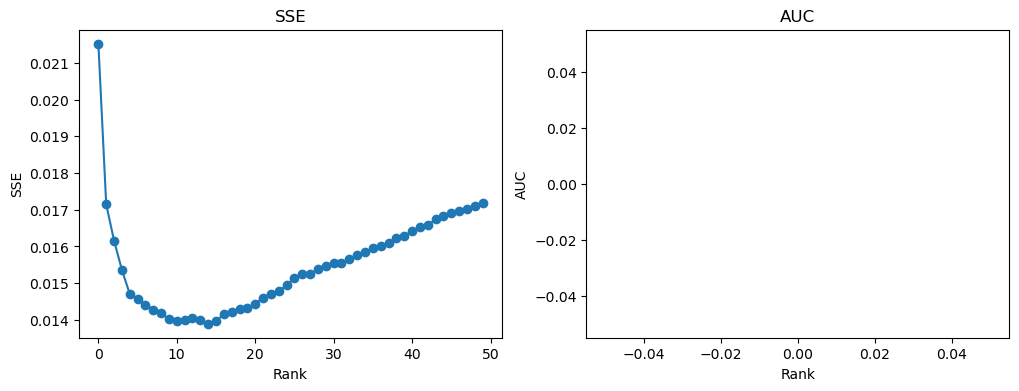

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ecv_res.sse, marker="o")
ax[0].set_title("SSE")
ax[0].set_xlabel("Rank")
ax[0].set_ylabel("SSE")
ax[1].plot(ecv_res.auc, marker="o")
ax[1].set_title("AUC")
ax[1].set_xlabel("Rank")
ax[1].set_ylabel("AUC")
plt.show()

### Marginal test network-party

In [47]:
test_1 = MultivariateACTest(k=15, solver=ASE)
data = {
    'A': A,
    'Y': party_cov.reshape(-1, 1),
}

test_1.fit(data, M=1, npermutations=2000, random_state=None, 
         permutation_type='covariates', alpha=0.05, verbose=True)

test_1.get_estimated()['p-value'], test_1.get_estimated()['reject_null']

(0.009900990099009901, True)

(0.009900990099009901, True)

In [38]:
test_sqrt = MultivariateACTest(k=15, solver=ASE)
data = {
    'A': A,
    'Y': party_cov.reshape(-1, 1),
}

test_sqrt.fit(data, M=100, n_permutations=10000, random_state=99, 
         permutation_type='covariates', alpha=0.05, verbose=True)

In [39]:
test_sqrt.get_estimated()['p-value'], test_sqrt.get_estimated()['reject_null']

(0.009900990099009901, True)